# The enhanced search vs plain alpha-beta (the deployed v4 search)

## Goal

Measure the deployed engine's search — `search.search_alpha_beta_with_quiescence`
(connect6/search.py): plain alpha-beta plus quiescence and forward pruning
(docs/EVALUATION.md, section 10) — against the plain `search.search_alpha_beta` it
extends, exactly as the evaluation chapter reports it:

- **Position tables** — nodes, wall time, score and move on the five documented positions
  at depths 2-4 (depths 1-3 for the completed-fork defence): the verdict exhibits, where
  quiescence prices a forced win or a lost defence at the terminal band while plain
  alpha-beta still oscillates in the mid-band, and the cost exhibits, where the pruning
  cuts the depth-4 trees.
- **Head-to-head games** — the section-10 referee protocol: depth 3, twelve games over six
  openings (white's first reply varied), color assignments alternated per game.

Weights are pinned to `tuning/winner.json`, the shipped champion — the exact configuration
the documentation measures. The searches are deterministic, so every node count, score and
move below reproduces docs/EVALUATION.md, section 10.2 exactly; only the wall-time column
varies between runs. The validation cells assert all of it — a clean run of this notebook
is a validation of the section-10 tables.

## Expected behaviour

The enhanced search must (1) find the fork-attack win a full depth earlier than plain
(depth 2 vs depth 3, 32 nodes vs 173), (2) price the completed-fork defence honestly from
depth 1, (3) get the five-run verdict right at every depth where plain oscillates
10,460 → 1,536 → 11,596, and (4) cut the quiet depth-4 trees roughly in half
(15,964 → 7,581 opening, 11,799 → 3,782 midgame). In the head-to-head fixture the shipped
configuration wins 11 of 12.

Runtime: about 10 minutes (the twelve depth-3 games dominate).

In [1]:
import os
import sys
import time
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tuning" / "default.json").is_file())
os.environ["WEIGHTS_FILE"] = str(ROOT / "tuning" / "winner.json")
sys.path.insert(0, str(ROOT / "tuning"))

import harness
from connect6.defines import GRID_NUM, MAXINT, Color, SearchStats
from connect6.protocol import move2msg
from connect6.search import search_alpha_beta, search_alpha_beta_with_quiescence

print(f"weights pinned to {os.environ['WEIGHTS_FILE']} (the shipped champion)")

weights pinned to /Users/e.butovka/Documents/MyProjects/Connect6Engine/tuning/winner.json (the shipped champion)


## Position tables

The five positions come from `tuning/harness.py` (`documented_positions`) — the same boards
behind the section-10 and section-11 tables. `win verdict` marks a score in the terminal
band (±20,000). Watch the three verdict positions: plain alpha-beta needs depth 3 for the
fork attack and never gets the five-run right at depths 2-4; enhanced is exact at every
depth. Watch the two quiet positions at depth 4: the pruning pays for the quiescence
leaves.

In [2]:
DEPTH_PLAN = {
    "opening scatter, white to move": (2, 3, 4),
    "midgame, white to move": (2, 3, 4),
    "fork attack, black to move": (2, 3, 4),
    "fork completed, white to move": (1, 2, 3),
    "five-run attack, white to move": (2, 3, 4),
}

table_rows = {}
for label, board, color, pre_move in harness.documented_positions():
    depths = DEPTH_PLAN.get(label)
    if depths is None:
        continue
    print(f"== {label} ==")
    print(f"{'method':9s} {'depth':5s} {'nodes':>7s} {'ms':>8s} {'score':>7s}  move")
    for depth in depths:
        for name, search in (("plain", search_alpha_beta), ("enhanced", search_alpha_beta_with_quiescence)):
            stats = SearchStats()
            start = time.perf_counter()
            result = search(board, color, depth, pre_move, stats)
            elapsed = (time.perf_counter() - start) * 1000
            marker = " <- win verdict" if result.score in (MAXINT, -MAXINT) else ""
            print(f"{name:9s} {depth:5d} {stats.node_count:7d} {elapsed:8.1f} {result.score:7d}  {move2msg(result.move)}{marker}")
            table_rows[(label, name, depth)] = (stats.node_count, result.score, move2msg(result.move))
    print()

== opening scatter, white to move ==
method    depth   nodes       ms   score  move
plain         2     164     22.6     -40  CIIP
enhanced      2     164     46.1     -40  CIIP


plain         3    1593    145.6    -436  CIIP


enhanced      3    1668    349.1    -386  CKJP


plain         4   15964   2403.8     -40  CKJP


enhanced      4    7581   2548.3     -38  CKJP

== midgame, white to move ==
method    depth   nodes       ms   score  move
plain         2     191     25.1    -134  FJII
enhanced      2     402    120.0    -134  FJII


...

plain         4   11799   2030.5    -305  FJKI


enhanced      4    3782   1577.3    -617  JGII

== fork attack, black to move ==
method    depth   nodes       ms   score  move
plain         2     173     30.7     742  FJJN
enhanced      2      32     20.2   20000  JNBJ <- win verdict
plain         3      78     20.5   20000  JNBJ <- win verdict
enhanced      3      78     27.7   20000  JNBJ <- win verdict
plain         4     347     47.8   20000  JNBJ <- win verdict


enhanced      4     179     69.9   20000  JNBJ <- win verdict

== fork completed, white to move ==
method    depth   nodes       ms   score  move
plain         1      31      2.6     742  JMFE
enhanced      1      31     21.1   20000  GJHJ <- win verdict
plain         2      77     27.5   20000  GJHJ <- win verdict
enhanced      2      77     33.1   20000  GJHJ <- win verdict
plain         3     347     53.2   20000  GJHJ <- win verdict


enhanced      3     207    123.1   20000  GJHJ <- win verdict

== five-run attack, white to move ==
method    depth   nodes       ms   score  move
plain         2      90     16.8   10460  HJBJ
enhanced      2      87     28.3   20000  HJBJ <- win verdict
plain         3     249     39.3    1536  HJBJ
enhanced      3     103     35.4   20000  HJBJ <- win verdict


plain         4    1616    217.9   11596  HJBJ
enhanced      4     110     33.4   20000  HJBJ <- win verdict



## Validation

The cell below re-checks every measured row against the documented table — the deterministic
fields only: nodes, score, move. Wall time is measured, not asserted.

In [3]:
EXPECTED_ROWS = {
    ("opening scatter, white to move", "plain", 2): (164, -40, "CIIP"),
    ("opening scatter, white to move", "enhanced", 2): (164, -40, "CIIP"),
    ("opening scatter, white to move", "plain", 3): (1593, -436, "CIIP"),
    ("opening scatter, white to move", "enhanced", 3): (1668, -386, "CKJP"),
    ("opening scatter, white to move", "plain", 4): (15964, -40, "CKJP"),
    ("opening scatter, white to move", "enhanced", 4): (7581, -38, "CKJP"),
    ("midgame, white to move", "plain", 2): (191, -134, "FJII"),
    ("midgame, white to move", "enhanced", 2): (402, -134, "FJII"),
    ("midgame, white to move", "plain", 3): (1425, -2342, "FJII"),
    ("midgame, white to move", "enhanced", 3): (1458, -703, "BJII"),
    ("midgame, white to move", "plain", 4): (11799, -305, "FJKI"),
    ("midgame, white to move", "enhanced", 4): (3782, -617, "JGII"),
    ("fork attack, black to move", "plain", 2): (173, 742, "FJJN"),
    ("fork attack, black to move", "enhanced", 2): (32, 20000, "JNBJ"),
    ("fork attack, black to move", "plain", 3): (78, 20000, "JNBJ"),
    ("fork attack, black to move", "enhanced", 3): (78, 20000, "JNBJ"),
    ("fork attack, black to move", "plain", 4): (347, 20000, "JNBJ"),
    ("fork attack, black to move", "enhanced", 4): (179, 20000, "JNBJ"),
    ("fork completed, white to move", "plain", 1): (31, 742, "JMFE"),
    ("fork completed, white to move", "enhanced", 1): (31, 20000, "GJHJ"),
    ("fork completed, white to move", "plain", 2): (77, 20000, "GJHJ"),
    ("fork completed, white to move", "enhanced", 2): (77, 20000, "GJHJ"),
    ("fork completed, white to move", "plain", 3): (347, 20000, "GJHJ"),
    ("fork completed, white to move", "enhanced", 3): (207, 20000, "GJHJ"),
    ("five-run attack, white to move", "plain", 2): (90, 10460, "HJBJ"),
    ("five-run attack, white to move", "enhanced", 2): (87, 20000, "HJBJ"),
    ("five-run attack, white to move", "plain", 3): (249, 1536, "HJBJ"),
    ("five-run attack, white to move", "enhanced", 3): (103, 20000, "HJBJ"),
    ("five-run attack, white to move", "plain", 4): (1616, 11596, "HJBJ"),
    ("five-run attack, white to move", "enhanced", 4): (110, 20000, "HJBJ"),
}

for key, expected in EXPECTED_ROWS.items():
    measured = table_rows[key]
    assert measured == expected, f"{key}: measured {measured}, documented {expected}"
print(f"all {len(EXPECTED_ROWS)} position rows reproduce section 10.2 exactly (nodes, score, move)")

all 30 position rows reproduce section 10.2 exactly (nodes, score, move)


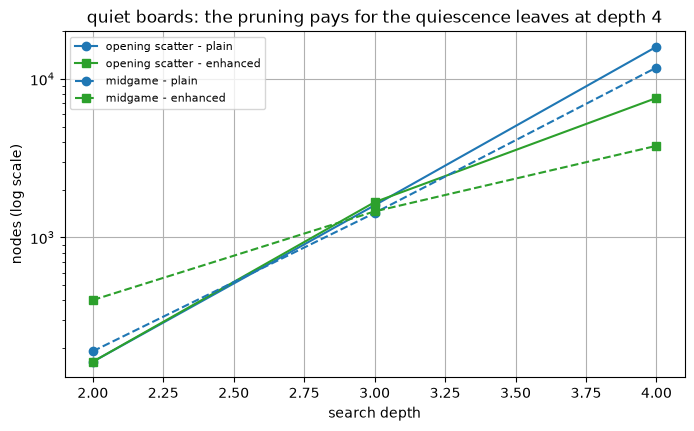

In [4]:
import matplotlib.pyplot as plt

quiet = ("opening scatter, white to move", "midgame, white to move")
fig, ax = plt.subplots(figsize=(8, 4.5))
styles = {quiet[0]: "-", quiet[1]: "--"}
for label in quiet:
    for name, color in (("plain", "tab:blue"), ("enhanced", "tab:green")):
        depths = DEPTH_PLAN[label]
        nodes = [table_rows[(label, name, d)][0] for d in depths]
        ax.plot(depths, nodes, marker="o" if name == "plain" else "s", color=color,
                linestyle=styles[label], label=f"{label.split(',')[0]} - {name}")
ax.set_yscale("log")
ax.set_xlabel("search depth")
ax.set_ylabel("nodes (log scale)")
ax.set_title("quiet boards: the pruning pays for the quiescence leaves at depth 4")
ax.grid(True)
ax.legend(fontsize=8)
plt.show()

## Head-to-head at the deployment depth

Both searches through the real referee (`harness.play_game`): center opening, white's first
reply forced to the six seeded openings, depth 3, 60-ply cap, the shipped champion weights
for both sides — the engines differ only in the search method. Deterministic engines, so
the twelve games are the complete fixture, not a sample. The shipped configuration's
documented record is 11-1 (section 10.2), the lone loss one color assignment of one
opening.

In [5]:
SEEDS = ["IIKK", "JIKJ", "JKJI", "IKKJ", "LLHH", "HHGG"]
GAMES = 2 * len(SEEDS)

plain_player = harness.search_player(search_alpha_beta)
enhanced_player = harness.search_player(search_alpha_beta_with_quiescence)

games = []
print(f"== head-to-head at depth 3 (enhanced vs plain, {GAMES} games over {len(SEEDS)} openings) ==")
for game in range(GAMES):
    seed = SEEDS[game % len(SEEDS)]
    enhanced_is_black = (game // len(SEEDS)) % 2 == 0
    black_player = enhanced_player if enhanced_is_black else plain_player
    white_player = plain_player if enhanced_is_black else enhanced_player
    start = time.perf_counter()
    record = harness.play_game(black_player, white_player, 3, white_first_reply=seed)
    elapsed = time.perf_counter() - start
    stones = sum(1 for x in range(1, GRID_NUM - 1) for y in range(1, GRID_NUM - 1) if record.board[x][y] != 0)
    if record.winner is None:
        outcome = "draw"
    else:
        enhanced_won = record.winner == (Color.BLACK if enhanced_is_black else Color.WHITE)
        outcome = "enhanced" if enhanced_won else "plain"
    games.append((seed, enhanced_is_black, outcome, stones))
    print(f"game {game + 1:2d}: opening {seed}, enhanced as {'black' if enhanced_is_black else 'white'}: {outcome:9s} {stones} stones, {elapsed:.1f} s")

== head-to-head at depth 3 (enhanced vs plain, 12 games over 6 openings) ==


game  1: opening IIKK, enhanced as black: enhanced  81 stones, 28.8 s


game  2: opening JIKJ, enhanced as black: enhanced  53 stones, 34.6 s


game  3: opening JKJI, enhanced as black: enhanced  97 stones, 66.8 s


game  4: opening IKKJ, enhanced as black: enhanced  41 stones, 16.7 s


...

game  8: opening JIKJ, enhanced as white: enhanced  83 stones, 61.5 s


game  9: opening JKJI, enhanced as white: enhanced  91 stones, 97.3 s


game 10: opening IKKJ, enhanced as white: enhanced  35 stones, 3.9 s


game 11: opening LLHH, enhanced as white: enhanced  55 stones, 38.5 s


game 12: opening HHGG, enhanced as white: plain     25 stones, 3.2 s


In [6]:
outcomes = [outcome for _, _, outcome, _ in games]
assert outcomes.count("enhanced") == 11, f"wins: {outcomes.count('enhanced')}"
assert outcomes.count("plain") == 1, f"losses: {outcomes.count('plain')}"
assert outcomes.count("draw") == 0
stones = [s for *_, s in games]
assert 25 <= min(stones) and max(stones) <= 97
print("head-to-head record reproduces section 10.2: enhanced wins 11-1 of 12, 25-97 stones")

head-to-head record reproduces section 10.2: enhanced wins 11-1 of 12, 25-97 stones


## Reading the results

- **Quiescence changes verdicts, not just moves** — the five-run defence is played by every
  search at every depth, but only the enhanced search ever calls it what it is: lost. Score
  and move decouple exactly as section 10.3 describes.
- **The extension horizon is real but bounded** — the fork attack is found one full depth
  earlier than plain; the six-ply extension fits the five-run chain exactly (fork, block,
  fork, block, unblockable fork, complete).
- **The pruning is a depth-4 dividend** — at depth 3 enhanced costs more wall time on quiet
  boards (the quiescence leaves pay candidate generation); at depth 4 it visits half the
  nodes. The deployment depth 3 is the worst case for the enhancement's economics and still
  the right trade for a tactical game.
- **The head-to-head record is protocol-relative** — center opening, depth 3, six openings:
  the same caveat sections 9 and 10 carry. Full discussion: docs/EVALUATION.md, sections
  10.3 and 10.5.